# Multimodal messages for agents
Until now every message I sent to an agent was **text**. In this notebook the same agent receives an **image** and an **audio** recording, with the same `create_agent` and the same `invoke`. Only the *message* changes.

Only `GOOGLE_API_KEY` is needed (from `.env`, Colab Secrets or pasted below). No OpenAI key is used. One Gemini model (`gemini-3.1-flash-lite`) accepts text, images and audio, so no separate audio model is needed.

**Idea:** the `content` of a message is not only a string, it can be a **list of blocks**. Each block has a `type`: `text`, `image` or `audio`.

**Text only:**
```
HumanMessage("What is the capital of The Moon?")
```

**Multimodal:** one message, several blocks.
```
HumanMessage(content=[
    {"type": "text",  "text": "Describe this image"},
    {"type": "image", "base64": "iVBORw0KGgo...", "mime_type": "image/png"},
])
```

**From a file to a message:** the API carries text, so the bytes of a file are first turned into text (**base64**).
```
file (bytes)  -->  base64 text  -->  content block (+ mime_type)  -->  HumanMessage  -->  agent
```
- **Block** = one part of a message (text, image or audio).
- **Base64** = a way to write any bytes as plain text.
- **`mime_type`** = tells the model what kind of file it received (`image/png`, `audio/wav`...).

## Setup

In [1]:
!pip install -q langchain langchain-google-genai python-dotenv ipywidgets tqdm
# Only to record from a microphone on your own computer (not needed in Colab):
# !pip install -q sounddevice

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.6/81.6 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.4/262.4 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 61.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.58.0 which is incompatible.


In [2]:
import os
from getpass import getpass
from dotenv import load_dotenv

load_dotenv()  # local run: reads the .env file (returns False if none is found)

KEYS = ("GOOGLE_API_KEY",)

# Colab run: read the keys from the Secrets panel (key icon in the left sidebar)
try:
    from google.colab import userdata
    for key in KEYS:
        try:
            os.environ[key] = userdata.get(key)
        except Exception:
            pass
except ImportError:
    pass

def is_real(value):
    # empty values and template placeholders ("your_..._here") count as missing
    return bool(value) and not value.startswith("your_")

# Still missing? Paste it here (hidden input).
for key in KEYS:
    if not is_real(os.getenv(key)):
        try:
            value = getpass(f"{key} is missing - paste it (Enter to skip): ").strip()
        except Exception:
            value = ""
        if value:
            os.environ[key] = value

for key in KEYS:
    print(f"{key}: {'set' if is_real(os.getenv(key)) else 'MISSING'}")

# Tracing with a placeholder LangSmith key only produces 401/403 warnings: switch it off
if not is_real(os.getenv("LANGSMITH_API_KEY")):
    os.environ["LANGSMITH_TRACING"] = "false"
    print("LangSmith tracing: off (no valid LANGSMITH_API_KEY)")

GOOGLE_API_KEY is missing - paste it (Enter to skip): ··········
GOOGLE_API_KEY: set
LangSmith tracing: off (no valid LANGSMITH_API_KEY)


In [3]:
import base64, io, os, sys, time, wave
from IPython.display import Image, display
from langchain.agents import create_agent
from langchain.messages import HumanMessage

MODEL = "google_genai:gemini-3.1-flash-lite"   # accepts text, images and audio

def show(title, text):
    print(f"\n{'=' * 12} {title} {'=' * 12}\n{text}")

def to_b64(data):
    """Bytes -> base64 text (the API carries text, so a file must be written as text)."""
    return base64.b64encode(data).decode("utf-8")

def show_blocks(blocks):
    """Print the blocks of a message WITHOUT dumping the base64 (thousands of characters)."""
    for i, b in enumerate(blocks):
        if "base64" in b:
            print(f"[{i}] {b['type']:5} mime_type={b['mime_type']}  base64={len(b['base64']):,} characters")
        else:
            print(f"[{i}] {b['type']:5} {b['text']!r}")

def tokens_in(response):
    """Input tokens used by the last AI message (what you pay for), or 'n/a'."""
    usage = getattr(response["messages"][-1], "usage_metadata", None) or {}
    return usage.get("input_tokens", "n/a")

BUSY = ("UNAVAILABLE", "RESOURCE_EXHAUSTED", "DEADLINE_EXCEEDED", "high demand", "overloaded")

def invoke_with_retry(agent, message, tries=5):
    """Run the agent. If the provider is busy (503, 429...), wait a little and try again."""
    for attempt in range(1, tries + 1):
        try:
            return agent.invoke({"messages": [message]})
        except Exception as e:
            busy = any(word.lower() in str(e).lower() for word in BUSY)
            if not busy or attempt == tries:
                raise
            wait = 2 ** attempt          # 2, 4, 8, 16 seconds
            print(f"Provider busy ({type(e).__name__}): attempt {attempt}/{tries} failed, retrying in {wait}s...")
            time.sleep(wait)

def ask(agent, blocks):
    """Send ONE human message made of content blocks; print the blocks, the input tokens and the answer."""
    print(f"\n{'=' * 12} Blocks sent {'=' * 12}")
    show_blocks(blocks)
    response = invoke_with_retry(agent, HumanMessage(content=blocks))
    show("Input tokens", tokens_in(response))
    show("Answer", response["messages"][-1].text)
    return response

## My files
This notebook uses two files of mine:
- `banner_dark_pink_contacts.png`: a banner image with text on it (1.3 MB).
- `liecio-calming-rain-257596.mp3`: 108 seconds of rain (3.5 MB).

**Jupyter:** put them in the same folder as the notebook (or in a folder called `assets`).
**Colab:** the notebook runs on a remote machine, so my PC files are not visible. Either drag the two files into the **Files** panel on the left (they land in `/content`), or just run the notebook: when a file is not found, a file dialog opens and I choose it. Colab forgets these files when the session ends.

`find_file()` looks in all these places, so the **same notebook runs in Jupyter and in Colab**.

In [4]:
IMAGE_FILE = "banner_dark_pink_contacts.png"
AUDIO_FILE = "liecio-calming-rain-257596.mp3"

def find_file(name):
    """Look for a file next to the notebook (Jupyter), in /content (Colab) or in an assets folder. Returns its path or None."""
    for folder in (".", "assets", "/content", "/content/assets"):
        path = os.path.join(folder, name)
        if os.path.isfile(path):
            return path
    return None

print("Working folder:", os.getcwd())
for name in (IMAGE_FILE, AUDIO_FILE):
    print(f"{name}: {find_file(name) or 'not found (a file dialog will open when needed)'}")

Working folder: /content
banner_dark_pink_contacts.png: not found (a file dialog will open when needed)
liecio-calming-rain-257596.mp3: not found (a file dialog will open when needed)


## Part 1: Text input
A message with only text is the simplest case: a list with **one text block**. A plain string is just a shortcut for it. The agent is the science fiction writer from notebook 1_1.

> **`HumanMessage(content=[{"type": "text", "text": "..."}])`**: a user message written as a list of blocks.  **`message.content_blocks`**: the content of any message written as a list of standard blocks.

In [5]:
agent = create_agent(
    model=MODEL,
    system_prompt="You are a science fiction writer, create a capital city at the user's request.",
)

blocks = [{"type": "text", "text": "What is the capital of The Moon?"}]

response = ask(agent, blocks)


============ Blocks sent ============
[0] text  'What is the capital of The Moon?'

============ Input tokens ============
27

============ Answer ============
In the year 2184, the capital of the Moon is **Artemis Prime**, often referred to by lunar colonists as "The Gilded Crater."

Here is a glimpse into the architecture and culture of this lunar metropolis:

### Location: The Shackleton Rim
Artemis Prime is built directly into the jagged, towering walls of the Shackleton Crater at the lunar south pole. This location was chosen for two reasons: the perpetual sunlight on the rim (which powers the city’s massive solar arrays) and the proximity to the ice deposits within the shadowed depths of the crater, which provide the city’s water and oxygen.

### The Architecture
The city is a hybrid of brutalist functionality and bioluminescent elegance. Because of the Moon’s low gravity, the buildings are impossibly tall and spindly, connected by transparent, pressurized vacuum-bridges that sn

In [6]:
# A plain string and a one-block list are the same message
print(HumanMessage("What is the capital of The Moon?").content_blocks)
print(HumanMessage(content=[{"type": "text", "text": "What is the capital of The Moon?"}]).content_blocks)

[{'type': 'text', 'text': 'What is the capital of The Moon?'}]
[{'type': 'text', 'text': 'What is the capital of The Moon?'}]


## Part 2: Image input
Three steps: **get the bytes** of an image, **encode** them in base64, then put them in an `image` block **next to a text block**.

### What is base64?
A file is bytes, but the API carries text. **Base64** writes any bytes with 64 safe characters (letters, digits, `+` and `/`, with `=` as padding). The idea, with a small text:

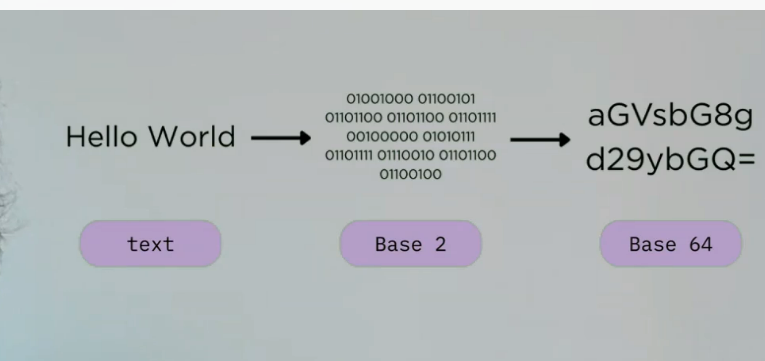

**Careful with the picture:** its base 2 line is for `Hello World` (capital H and W), but its base 64 (`aGVsbG8g d29ybGQ=`) is the one of the lowercase `hello world`. Different letters give different base 64. Run the cell below to see both.

> **`base64.b64encode(bytes)`**: bytes to base64. **`base64.b64decode(text)`**: back to the same bytes. It is **not** encryption: anyone can decode it.

In [7]:
for text in ("Hello World", "hello world"):
    raw = text.encode("utf-8")                       # text -> bytes
    bits = " ".join(f"{b:08b}" for b in raw)         # bytes -> base 2 (what the computer stores)
    b64 = base64.b64encode(raw).decode("ascii")      # bytes -> base 64
    print(f"text    : {text}")
    print(f"base 2  : {bits}")
    print(f"base 64 : {b64}")
    print(f"decoded : {base64.b64decode(b64).decode('utf-8')}")
    print()

text    : Hello World
base 2  : 01001000 01100101 01101100 01101100 01101111 00100000 01010111 01101111 01110010 01101100 01100100
base 64 : SGVsbG8gV29ybGQ=
decoded : Hello World

text    : hello world
base 2  : 01101000 01100101 01101100 01101100 01101111 00100000 01110111 01101111 01110010 01101100 01100100
base 64 : aGVsbG8gd29ybGQ=
decoded : hello world



A picture works the same way: a PNG file is only bytes, so it also becomes base64 text. Every PNG starts with `iVBORw0KGgo`, you will see it below.

### Helpers
Small helpers used here and in Part 3. In Colab a file dialog opens; on my own computer an upload button appears.

> **`mime_of(filename)`**: the `mime_type` that goes with the file extension. It must match the real file: a `.jpg` sent as `image/png` is a mistake.

In [8]:
MIME = {
    ".png": "image/png", ".jpg": "image/jpeg", ".jpeg": "image/jpeg", ".webp": "image/webp",
    ".wav": "audio/wav", ".mp3": "audio/mpeg", ".ogg": "audio/ogg", ".flac": "audio/flac",
}

def mime_of(filename):
    ext = os.path.splitext(filename)[1].lower()
    if ext not in MIME:
        raise ValueError(f"Unsupported file type {ext!r}. Use one of: {', '.join(MIME)}")
    return MIME[ext]

MAX_MB = 15   # a file sent inline must stay small: the whole request is limited (about 20 MB) and base64 adds a third

def check_size(filename, data):
    """Print the size of a file and stop if it is too big to send inline."""
    mb = len(data) / 1_000_000
    print(f"{filename}: {len(data):,} bytes ({mb:.1f} MB), mime_type = {mime_of(filename)}")
    if mb > MAX_MB:
        raise ValueError(
            f"{filename} is {mb:.0f} MB, above MAX_MB = {MAX_MB}. Use a shorter or smaller file "
            "(a clip of a minute or two is plenty here), or raise MAX_MB at your own risk."
        )

IN_COLAB = "google.colab" in sys.modules
_uploader, _colab_files = None, {}

def ask_for_file(accept):
    """Colab: opens a file dialog. Jupyter: shows an upload button (choose a file, then run the next cell)."""
    global _uploader, _colab_files
    if IN_COLAB:
        from google.colab import files
        _colab_files = files.upload()
    else:
        from ipywidgets import FileUpload
        _uploader = FileUpload(accept=accept, multiple=False)
        display(_uploader)

def read_upload():
    """Return (filename, bytes) of the file just chosen, or None. It can be read only once."""
    global _uploader, _colab_files
    if IN_COLAB:
        items = list(_colab_files.items())
        _colab_files = {}
    elif _uploader is None:
        items = []
    else:
        value = _uploader.value
        if isinstance(value, dict):   # ipywidgets 7: {filename: {"content": ...}}
            items = [(name, f["content"]) for name, f in value.items()]
        else:                         # ipywidgets 8: tuple of {"name": ..., "content": ...}
            items = [(f["name"], f["content"]) for f in value]
        _uploader = None
    return (items[0][0], bytes(items[0][1])) if items else None

def sample_image(width=480, height=300):
    """A small drawn picture of a lunar city, written as a PNG in pure Python (no extra package).
    Used when no image is uploaded."""
    import struct, zlib
    stars = [(40, 40), (120, 80), (200, 30), (300, 70), (250, 110), (80, 120)]
    domes = [(105, 45), (250, 60), (380, 40)]      # (centre x, radius), sitting on the ground line
    ground_y = 230
    rows = bytearray()
    for y in range(height):
        rows.append(0)                             # PNG filter byte: none
        for x in range(width):
            if y >= ground_y:
                px = (138, 138, 138)               # grey lunar ground
            elif (x - 400) ** 2 + (y - 60) ** 2 <= 40 ** 2:
                px = (74, 144, 226)                # Earth in the sky
            elif any((x - cx) ** 2 + (y - ground_y) ** 2 <= r ** 2 for cx, r in domes):
                px = (159, 211, 255)               # glass domes
            elif any((x - sx) ** 2 + (y - sy) ** 2 <= 4 for sx, sy in stars):
                px = (255, 255, 255)               # stars
            else:
                px = (11, 16, 48)                  # night sky
            rows += bytes(px)

    def chunk(tag, data):
        body = tag + data
        return struct.pack(">I", len(data)) + body + struct.pack(">I", zlib.crc32(body) & 0xFFFFFFFF)

    signature = bytes([137, 80, 78, 71, 13, 10, 26, 10])
    header = struct.pack(">IIBBBBB", width, height, 8, 2, 0, 0, 0)     # 8 bit, RGB
    return signature + chunk(b"IHDR", header) + chunk(b"IDAT", zlib.compress(bytes(rows))) + chunk(b"IEND", b"")

### Task 1: send an image with a question
**Step 1: get the image.** The next cell looks for `banner_dark_pink_contacts.png` (next to the notebook, in `/content`, or in `assets`). If it is not there, a file dialog opens (Colab) or an upload button appears (Jupyter: choose the file, **then** run the cell after). No image at all? A drawn sample is used, so the notebook never stops.

In [9]:
img_path = find_file(IMAGE_FILE)

if img_path:
    print("Found:", img_path)
else:
    print(f"{IMAGE_FILE} not found -> choose the file")
    ask_for_file(".png,.jpg,.jpeg,.webp")     # Colab: dialog opens. Jupyter: upload button

banner_dark_pink_contacts.png not found -> choose the file


Saving banner_dark_pink_contacts.png to banner_dark_pink_contacts.png


banner_dark_pink_contacts.png: 1,332,721 bytes (1.3 MB), mime_type = image/png


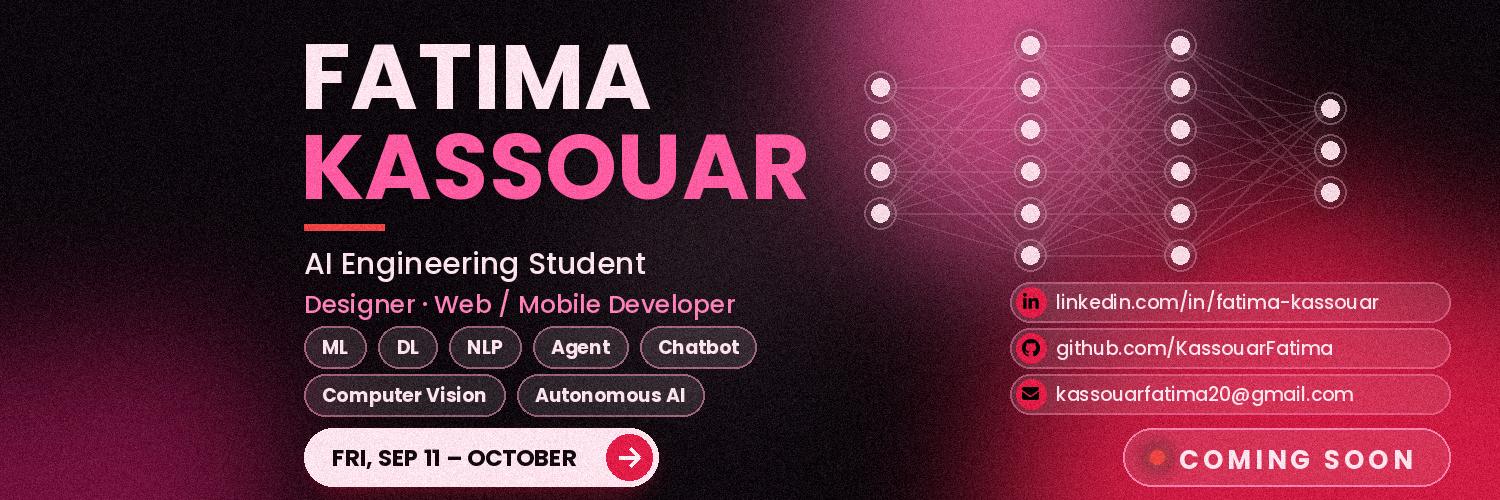

In [10]:
if img_path:
    img_name, img_bytes = os.path.basename(img_path), open(img_path, "rb").read()
else:
    upload = read_upload()
    if upload is None:
        print("No file chosen -> using a drawn sample image")
        img_name, img_bytes = "sample.png", sample_image()
    else:
        img_name, img_bytes = upload

check_size(img_name, img_bytes)
display(Image(data=img_bytes, width=500))

**Step 2: encode and build the message.** One human message, two blocks: the text and the image. A plain agent (no system prompt) is enough.

> **`{"type": "image", "base64": ..., "mime_type": ...}`**: an image block. The file is base64 text, so it is about a third bigger than the file itself.

In [11]:
agent_plain = create_agent(model=MODEL)

img_b64 = to_b64(img_bytes)
print("base64 starts with:", img_b64[:12] + "...")

image_block = {"type": "image", "base64": img_b64, "mime_type": mime_of(img_name)}

multimodal_question = [
    {"type": "text", "text": "Describe this image in two sentences."},
    image_block,
]

response_image = ask(agent_plain, multimodal_question)

base64 starts with: iVBORw0KGgoA...

============ Blocks sent ============
[0] text  'Describe this image in two sentences.'
[1] image mime_type=image/png  base64=1,776,964 characters

============ Input tokens ============
1091

============ Answer ============
This professional banner features Fatima Kassouar, an AI engineering student and developer, showcasing her technical expertise in fields like machine learning, NLP, and computer vision. The dark, sleek design incorporates a neural network graphic and provides her contact information, including social media links and an email address.


### Task 2: what does the image add?
Ask **the same question without the image**. Compare the answer and the **input tokens**: the picture is part of what you pay for.

In [12]:
response_text = ask(agent_plain, [{"type": "text", "text": "Describe this image in two sentences."}])

show("Input tokens: text only vs with image", f"{tokens_in(response_text)}  vs  {tokens_in(response_image)}")


============ Blocks sent ============
[0] text  'Describe this image in two sentences.'

============ Input tokens ============
8

============ Answer ============
Please provide or upload the image you are referring to! Once you share it, I will be happy to describe it for you in two sentences.

============ Input tokens: text only vs with image ============
8  vs  1091


Without the picture the agent has nothing to describe: it says it sees no image, or it invents something. With the picture it describes what it **sees**. The agent did not change, only the message.

### Task 3: read the text inside the image
The text block is the instruction, the image block is the data. Change only the question: the model can **read** the words written in the picture.

In [13]:
read_question = [
    {"type": "text", "text": "Read this banner: give the name, the title, the skills and the links written on it."},
    image_block,
]

response_read = ask(agent_plain, read_question)


============ Blocks sent ============
[0] text  'Read this banner: give the name, the title, the skills and the links written on it.'
[1] image mime_type=image/png  base64=1,776,964 characters

============ Input tokens ============
1104

============ Answer ============
Based on the banner provided, here is the information requested:

**Name:**
Fatima Kassouar

**Title:**
AI Engineering Student / Designer / Web & Mobile Developer

**Skills:**
* ML (Machine Learning)
* DL (Deep Learning)
* NLP (Natural Language Processing)
* Agent
* Chatbot
* Computer Vision
* Autonomous AI

**Links/Contact Info:**
* **LinkedIn:** linkedin.com/in/fatima-kassouar
* **GitHub:** github.com/KassouarFatima
* **Email:** kassouarfatima20@gmail.com


## Part 3: Audio input
Same idea, with an `audio` block. I need the bytes of a recording. The cells choose the source for me:
1. **The audio file** (default): `liecio-calming-rain-257596.mp3`, found next to the notebook or chosen in the dialog. **Works in Jupyter and in Colab.**
2. **The microphone:** set `USE_MICROPHONE = True` to record 5 seconds. It works on my own computer, **not in Colab** (the notebook runs on a remote machine without a microphone). If it fails, the file is used instead.
3. **Fallback:** a 2 second test tone, so the cell never stops.

**Keep the file small.** The file is sent inside the request, and the request has a size limit (about 20 MB, and base64 adds a third). `check_size()` stops files above `MAX_MB`. A clip of a minute or two is plenty (a 1 minute MP3 is roughly 1 MB). A 25 MB recording is a job for the provider's file upload service, not for this notebook.

> **`{"type": "audio", "base64": ..., "mime_type": "audio/mpeg"}`**: an audio block (`audio/wav` for a WAV file).  **`int16`**: 16-bit samples, the most widely accepted WAV format. I record at 16 000 Hz, enough for speech and small to send.

In [14]:
def wav_bytes_from(samples, sample_rate):
    """16-bit mono samples (bytes) -> the bytes of a WAV file, built in memory."""
    buf = io.BytesIO()
    with wave.open(buf, "wb") as w:
        w.setnchannels(1)
        w.setsampwidth(2)          # 2 bytes = 16 bit
        w.setframerate(sample_rate)
        w.writeframes(samples)
    return buf.getvalue()

def record_audio(seconds=5, sample_rate=16000):
    """Record from the microphone (own computer only). Returns WAV bytes."""
    import sounddevice as sd
    try:
        from tqdm.auto import tqdm
    except ImportError:                      # no progress bar available: just wait
        tqdm = lambda x: x
    print("Recording... speak now")
    audio = sd.rec(int(seconds * sample_rate), samplerate=sample_rate, channels=1, dtype="int16")
    for _ in tqdm(range(seconds * 10)):      # progress bar, updated 10 times per second
        time.sleep(0.1)
    sd.wait()
    print("Done.")
    return wav_bytes_from(audio.tobytes(), sample_rate)

def test_tone(seconds=2, freq=440, sample_rate=16000):
    """A simple beep (440 Hz), used when there is no recording and no upload."""
    import math, struct
    samples = b"".join(
        struct.pack("<h", int(12000 * math.sin(2 * math.pi * freq * i / sample_rate)))
        for i in range(seconds * sample_rate)
    )
    return wav_bytes_from(samples, sample_rate)

### Task 4: send an audio file with a question
**Step 1: get the audio.** Same logic as for the image. To record my own voice on my computer, set `USE_MICROPHONE = True` and say a short sentence, for example *"Hello, my name is Fatima and I am learning to build agents."*

In [15]:
USE_MICROPHONE = False   # True: record 5 seconds on my own computer (not in Colab)

aud_name, aud_bytes, aud_path = AUDIO_FILE, None, None

if USE_MICROPHONE:
    try:
        aud_name, aud_bytes = "recording.wav", record_audio(5)
    except Exception as e:
        print(f"No microphone available here ({type(e).__name__}) -> using the audio file instead.")

if aud_bytes is None:
    aud_path = find_file(AUDIO_FILE)
    if aud_path:
        print("Found:", aud_path)
    else:
        print(f"{AUDIO_FILE} not found -> choose the file")
        ask_for_file(".wav,.mp3,.ogg,.flac")  # Colab: dialog opens. Jupyter: upload button

liecio-calming-rain-257596.mp3 not found -> choose the file


Saving liecio-calming-rain-257596.mp3 to liecio-calming-rain-257596.mp3


In [16]:
if aud_bytes is None and aud_path:
    aud_name, aud_bytes = os.path.basename(aud_path), open(aud_path, "rb").read()
elif aud_bytes is None:
    upload = read_upload()
    if upload is not None:
        aud_name, aud_bytes = upload

if aud_bytes is None:
    print("No recording and no file -> using a 2 second test tone")
    aud_name, aud_bytes = "tone.wav", test_tone()

check_size(aud_name, aud_bytes)

liecio-calming-rain-257596.mp3: 3,477,420 bytes (3.5 MB), mime_type = audio/mpeg


**Step 2: build the message**, with the same two-block shape as for the image. The plain agent from Part 2 is reused.

In [17]:
audio_block = {"type": "audio", "base64": to_b64(aud_bytes), "mime_type": mime_of(aud_name)}

audio_question = [
    {"type": "text", "text": "Tell me about this audio file"},
    audio_block,
]

response_audio = ask(agent_plain, audio_question)


============ Blocks sent ============
[0] text  'Tell me about this audio file'
[1] audio mime_type=audio/mpeg  base64=4,636,560 characters

============ Input tokens ============
2724

============ Answer ============
The audio file contains a low, consistent, humming sound that feels like a steady mechanical whirring, almost like a ventilation fan or a distant engine. It doesn't fluctuate in volume or speed, creating a constant, somewhat monotonous background drone that persists through the entire recording.


### Task 5: same audio, a different question
The audio stays the same, only the text block changes. Ask for a **transcript**: the text block is the instruction, the audio block is the data. The rain has no speech, so the model should say what it hears instead.

In [18]:
transcript_question = [
    {"type": "text", "text": "Transcribe exactly what is said. If there is no speech, say what you hear instead."},
    audio_block,
]

response_transcript = ask(agent_plain, transcript_question)


============ Blocks sent ============
[0] text  'Transcribe exactly what is said. If there is no speech, say what you hear instead.'
[1] audio mime_type=audio/mpeg  base64=4,636,560 characters

============ Input tokens ============
2737

============ Answer ============
[birds chirping]


## What I learned
1. **A message can hold more than text.** Its `content` is a list of **blocks**, and each block has a `type`: `text`, `image` or `audio`. A plain string is a shortcut for one text block.
2. **The agent code does not change.** `create_agent` and `agent.invoke({"messages": [...]})` are the same as before. Only the message is different.
3. **A file becomes a block in three steps:** get the bytes, encode them in **base64** (the API carries text), and add the `mime_type` so the model knows what it is. Base64 only changes the alphabet: it is not encryption, and `Hello World` and `hello world` give different results.
4. **The `mime_type` must match the file** (`image/png` for a PNG, `audio/wav` for a WAV).
5. **The model must accept that input.** Not every model reads images or audio: check the provider's model page. Here one Gemini model handles text, images and audio, so the same `MODEL` is used in every part. Model list: https://ai.google.dev/gemini-api/docs/models
6. **Files are sent inside the request, so keep them small.** The request has a size limit (about 20 MB) and base64 adds a third. `check_size()` stops a file that is too big before it is sent.
7. **Images and audio cost tokens.** Compare `input_tokens` with and without the image: the file is part of what you pay for.
8. **Do not print the whole message.** The base64 of a file is thousands of characters, so `show_blocks()` prints only the type, the `mime_type` and the size.
9. **The text block is the instruction, the file block is the data.** Change the question and keep the same file to get a description, a transcript or an answer.

**Mistakes to avoid:**
- Looking for my files on my PC while running in **Colab**: they are not there. Drag them into the Files panel (`/content`) or use the file dialog, and remember that Colab forgets them when the session ends.
- A **503 `UNAVAILABLE` "high demand"** error is the provider being busy, not a bug in my code. `ask()` retries automatically (2, 4, 8, 16 seconds). If it still fails, wait a minute and run the cell again. A huge file makes it more likely.
- Sending a file of 25 MB or more: use a short clip instead.
- Recording with `sounddevice` in Colab: the notebook runs on a remote machine without a microphone. Upload a file instead.
- Running the next cell before choosing the file in the Jupyter upload button: `read_upload()` then finds nothing and the sample is used.
- Sending a file with the wrong `mime_type`, or a format the model does not accept (I used `.png`, `.jpg`, `.webp`, `.wav`, `.mp3`, `.ogg`, `.flac`).
- Sending private pictures or recordings: the file leaves my computer and goes to the provider.
- Never share API keys (revoke and recreate any key that leaks); run the cells from the top; in Colab the `.env` file on your PC is not visible, use Secrets or paste the key.

## Summary of functions
| Function / class | Simple definition |
|---|---|
| `HumanMessage(content=[...])` | A user message whose content is a **list of blocks** instead of a string. |
| `{"type": "text", "text": "..."}` | A text block. |
| `{"type": "image", "base64": ..., "mime_type": ...}` | An image block (base64 text plus the file type). |
| `{"type": "audio", "base64": ..., "mime_type": ...}` | An audio block (base64 text plus the file type). |
| `message.content_blocks` | The content of a message as a list of standard blocks. |
| `base64.b64encode(data).decode("utf-8")` | Turns the bytes of a file into base64 text. |
| `create_agent(model)` | Builds an agent. The same agent reads text, images and audio if the model accepts them. |
| `agent.invoke({"messages": [message]})` | Runs the agent on a multimodal message. |
| `response["messages"][-1].text` | The final answer as plain text. |
| `usage_metadata["input_tokens"]` | Tokens sent to the model (images and audio included). |
| `FileUpload` (ipywidgets) / `files.upload()` (Colab) | Lets me choose a file from my computer. |
| `sounddevice.rec(...)` | Records from the microphone (own computer only). |
| `wave.open(buf, "wb")` | Writes WAV data (from the standard library, no extra package). |
| `show()`, `to_b64()`, `show_blocks()`, `tokens_in()`, `ask()` | Helpers written in this notebook to print a title, encode bytes, list blocks without the base64, read tokens, and send blocks to an agent. |
| `mime_of()`, `ask_for_file()`, `read_upload()` | Helpers to find the file type and to get a file in Colab or Jupyter. |
| `find_file(name)` | Looks for a file next to the notebook, in `/content` (Colab) or in `assets`, and returns its path or `None`. |
| `IMAGE_FILE`, `AUDIO_FILE`, `USE_MICROPHONE` | The two files used by the notebook, and the switch to record with the microphone instead. |
| `tqdm(range(n))` | A progress bar while the microphone records. |
| `sample_image()`, `record_audio()`, `test_tone()`, `wav_bytes_from()` | Helpers that draw a sample image (pure Python), record audio, make a test beep and build WAV bytes. |
| `check_size()`, `MAX_MB` | Stops a file that is too big to be sent inside the request. |
| `invoke_with_retry()` | Runs the agent and tries again (2, 4, 8, 16 s) when the provider answers 503 or 429. |

By
> Kassouar Fatima                   24-09-2026